# SHIFT-SURV — rebuilding the paper figures

Every figure in the paper is produced by a script in `paper_assets/` that reads
result tables from `outputs/tables/`. Those tables are tracked in this repository,
so this notebook runs end to end without rerunning any experiment.

Run the cells in order. Each one runs one generator, reports which files it wrote,
and displays them. A generator whose input tables are missing reports what it
needs and the notebook continues.

To regenerate the tables themselves, see the pipeline section of `README.md`.

In [1]:
import subprocess, sys, time
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path.cwd()
while not (ROOT / 'paper_assets').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
TABLES = ROOT / 'outputs' / 'tables'
FIGS   = ROOT / 'outputs' / 'figures' / 'paper'
FIGS.mkdir(parents=True, exist_ok=True)
print('repository :', ROOT)
print('tabelle    :', len(list(TABLES.glob('*.csv'))), 'file CSV')
print('python     :', sys.version.split()[0])

repository : /home/ludovica/shift-surv-benchmark
tabelle    : 1474 file CSV
python     : 3.10.20


## Helper

`run(script)` executes one generator and shows the figures it wrote. Newly written
files are detected by modification time, so the notebook stays correct when a
generator is renamed or starts producing an extra panel.

In [2]:
def run(script, args=(), show=True, width=560):
    """Run one figure generator and display whatever it wrote."""
    t0 = time.time() - 1
    cmd = [sys.executable, str(ROOT / 'paper_assets' / script), *map(str, args)]
    p = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
    if p.returncode != 0:
        tail = (p.stderr or p.stdout).strip().splitlines()[-6:]
        display(Markdown(f'**{script} non ha completato.** Ultime righe:'))
        print('\n'.join(tail))
        return []
    if p.stdout.strip():
        print(p.stdout.strip())
    fresh = sorted(f for f in FIGS.glob('*.png') if f.stat().st_mtime >= t0)
    if not fresh:
        display(Markdown(f'_{script}: nessuna figura nuova._'))
    for f in fresh:
        display(Markdown(f'**{f.name}**'))
        if show:
            display(Image(filename=str(f), width=width))
    return fresh

## 1. Synthetic benchmark

Discrimination and calibration per shift regime, under the adaptation protocol
(one source centre) and the domain-generalization protocol (three source centres).

Inputs: `benchmark_1s1t_iwcv_*`, `benchmark_1s1t_prior_summary`,
`benchmark_3s1t_*`, `benchmark_3s1t_prior_summary`.

scritto /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_disc_a.{pdf,png}
  scritto /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_disc_b.{pdf,png}


**fig_disc_a.png**

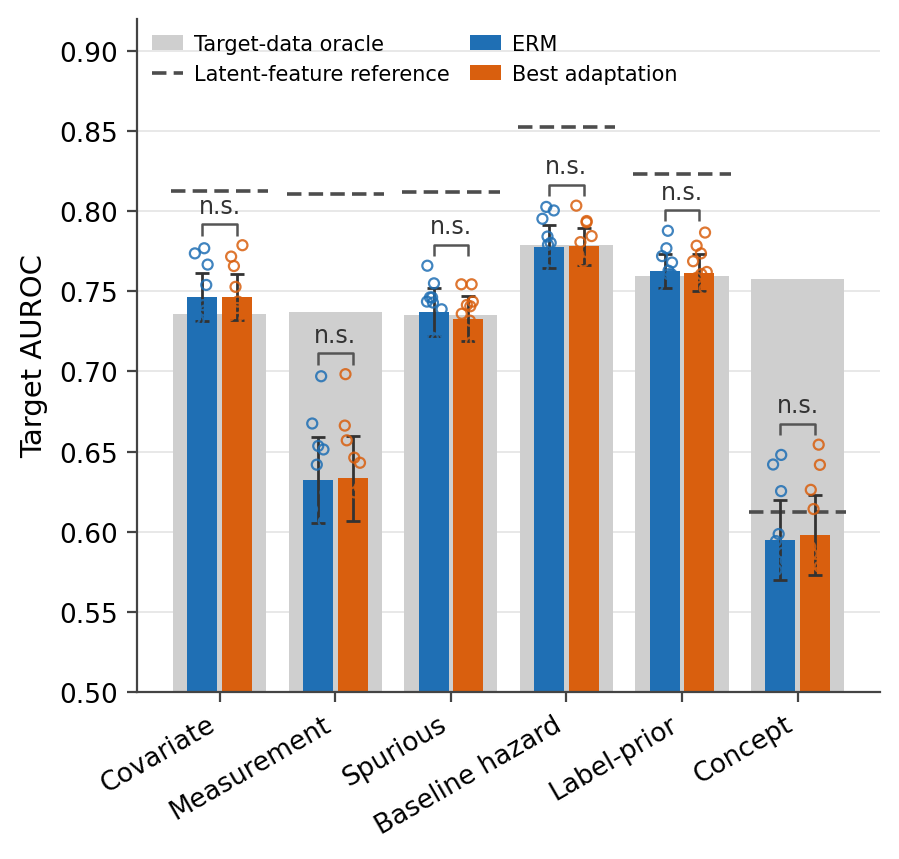

**fig_disc_b.png**

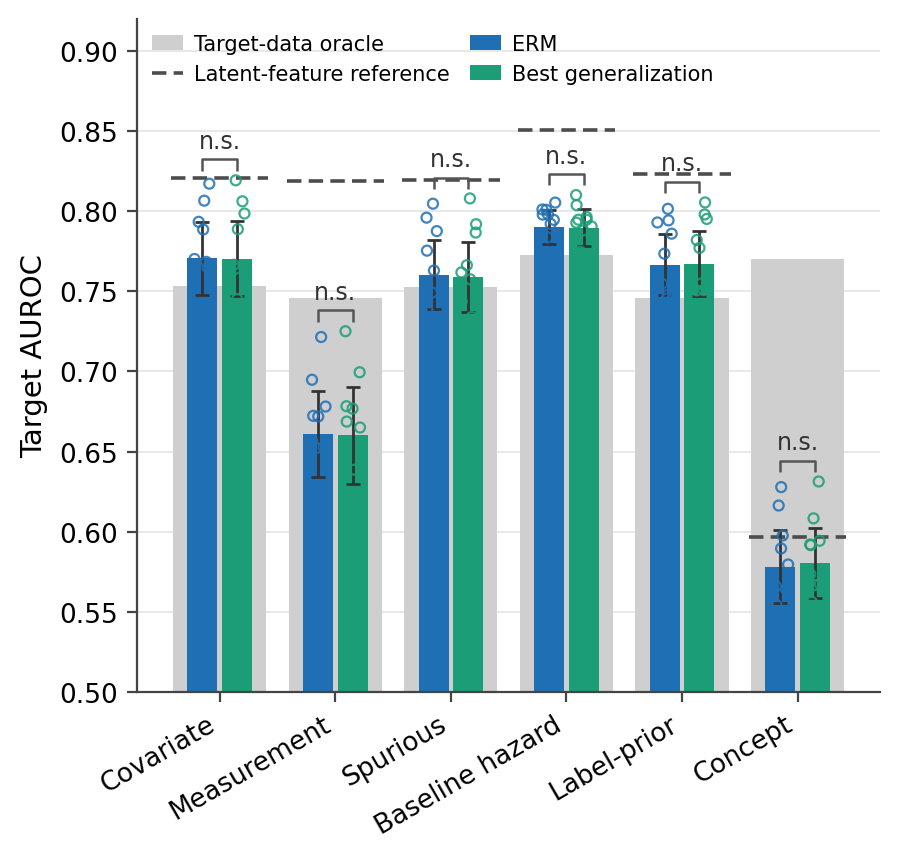

[PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_disc_a.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_disc_b.png')]

In [3]:
run('_gen_fig_disc.py')

scritto /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_cal_a.{pdf,png}

  RIGA DA AGGIUNGERE ALLA DIDASCALIA di fig:cal panel a:
    The bracket spans the compared methods and the star is the family-level max-statistic result; the method attaining it is DANN under measurement shift (*); prior adjustment under label-prior shift (***); CDAN under concept shift (**).
  scritto /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_cal_b.{pdf,png}

  RIGA DA AGGIUNGERE ALLA DIDASCALIA di fig:cal panel b:
    The bracket spans the compared methods and the star is the family-level max-statistic result; the method attaining it is IRM under baseline-hazard shift (***); IRM under label-prior shift (***); IRM under concept shift (***).


**fig_cal_a.png**

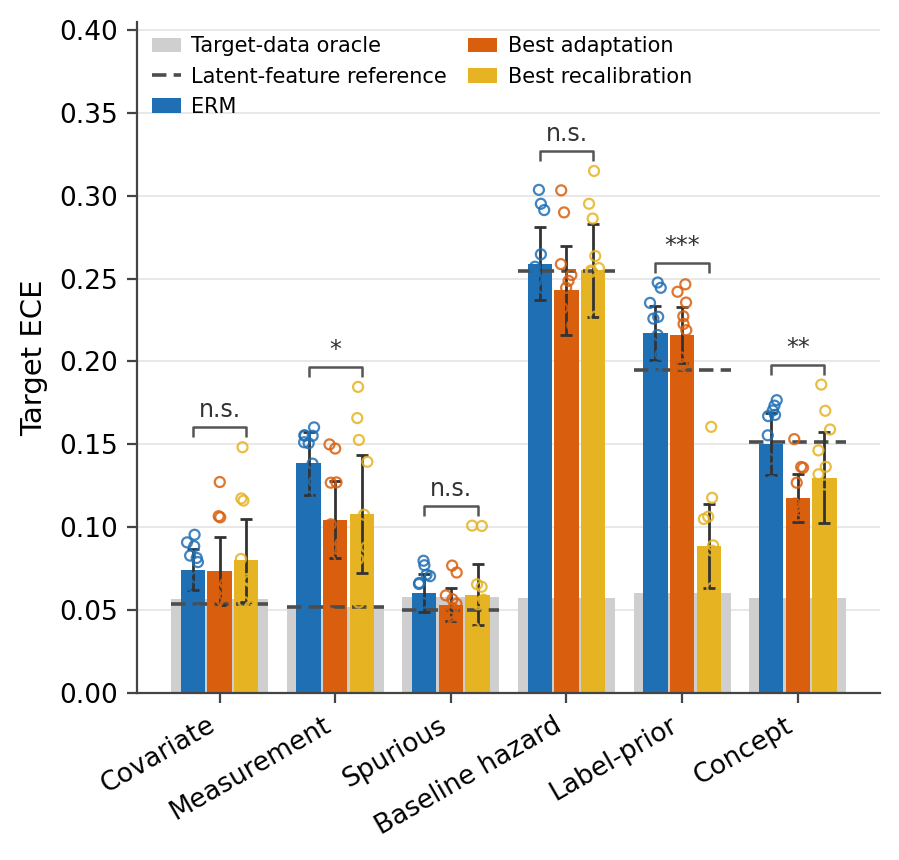

**fig_cal_b.png**

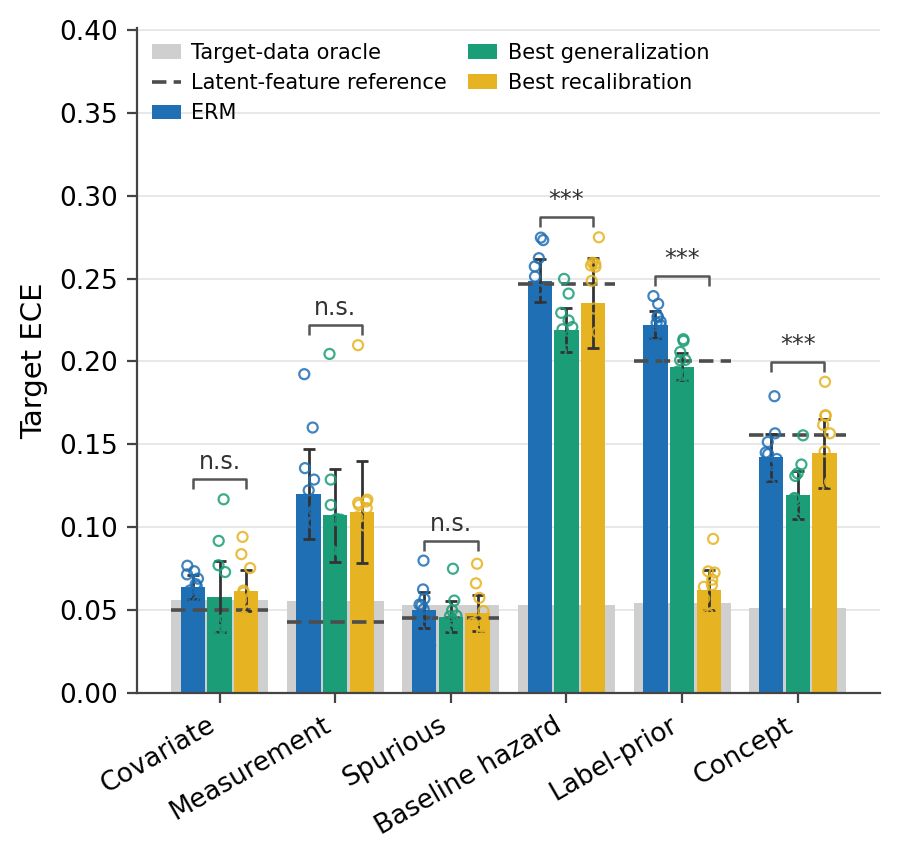

**fig_disc_a.png**

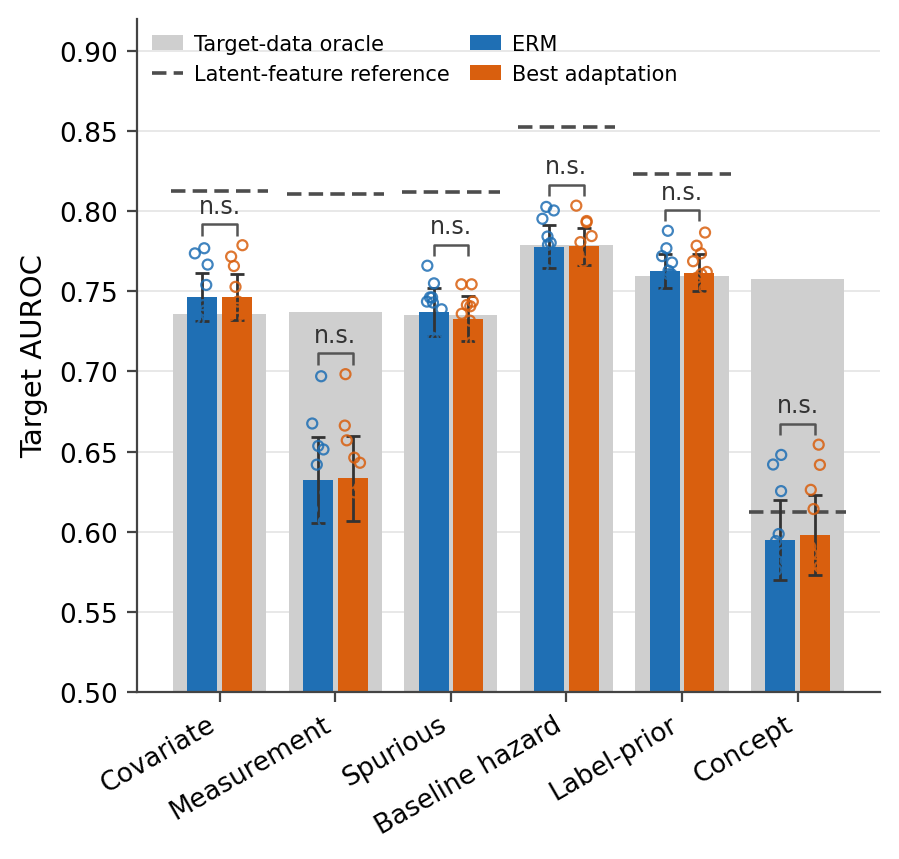

**fig_disc_b.png**

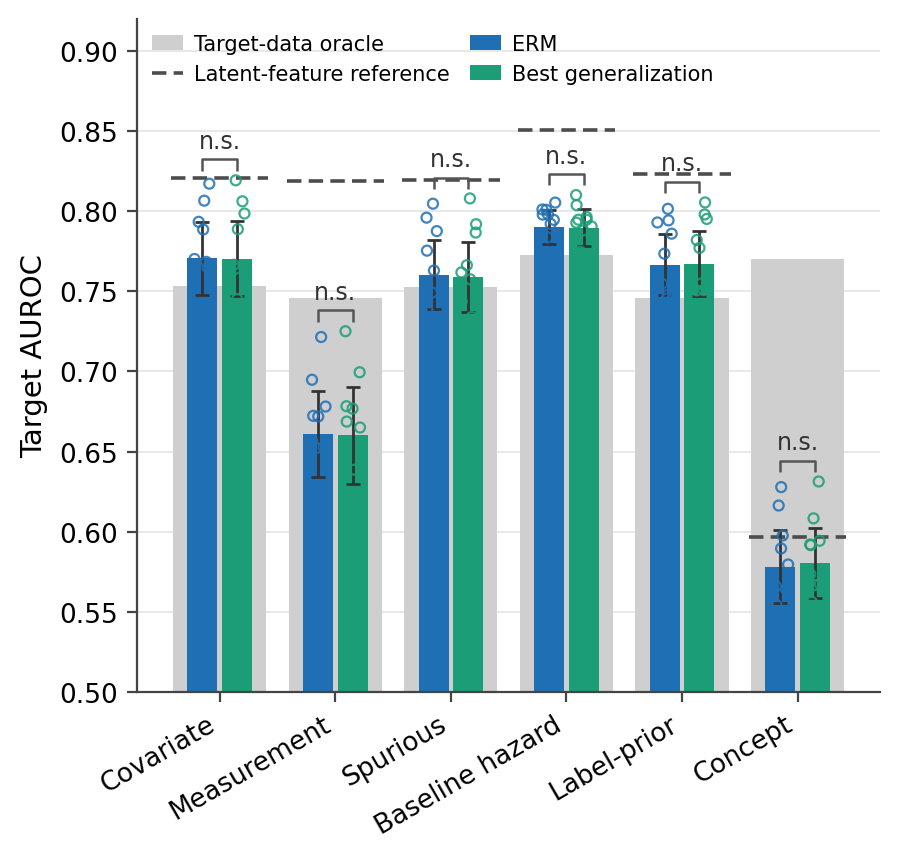

[PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_cal_a.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_cal_b.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_disc_a.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_disc_b.png')]

In [4]:
run('_gen_fig_cal.py')

## 2. Real cohorts

Pooled effects on the I3LUNG transfers and on the Rotterdam–GBSG2 registry.

Inputs: `i3lung_meta.csv`, `i3lung_loco_meta.csv`, `public_rotterdam_gbsg_meta.csv`.

scritto /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_realmain.{pdf,png}
    I3LUNG Adaptation               k=6         (6 target cohorts, 30 directed transfers)
    I3LUNG Domain Generalization    k=6         (6 held-out centres)
    Registry Adaptation             unpooled    (2 directed transfers)


**fig_cal_a.png**

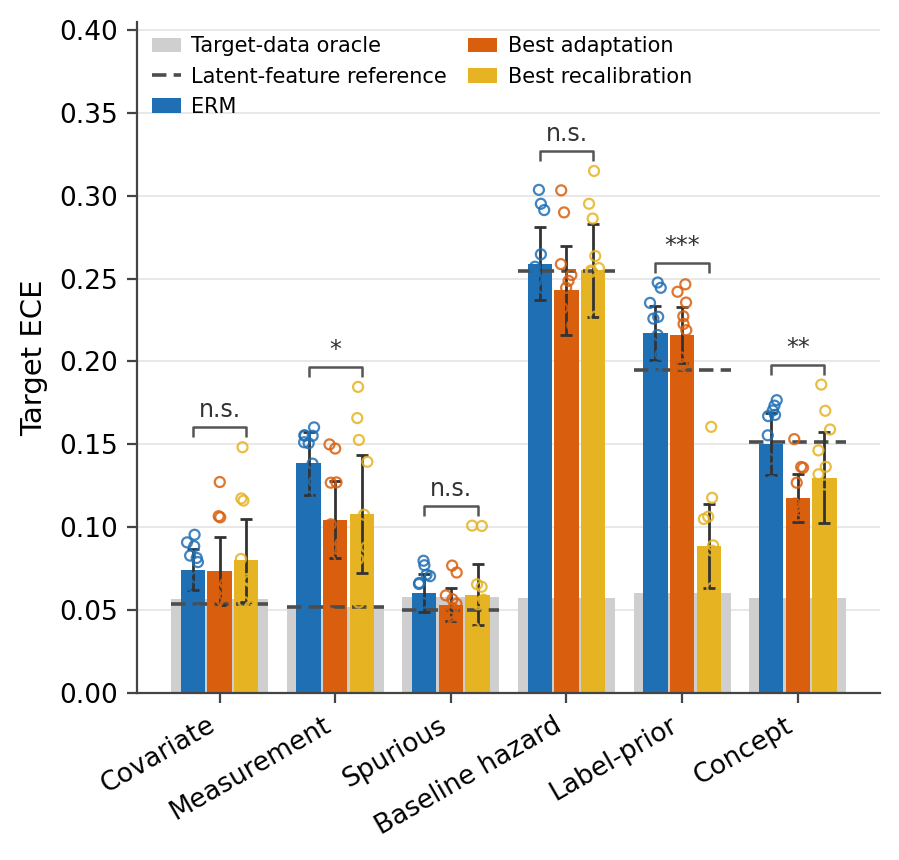

**fig_cal_b.png**

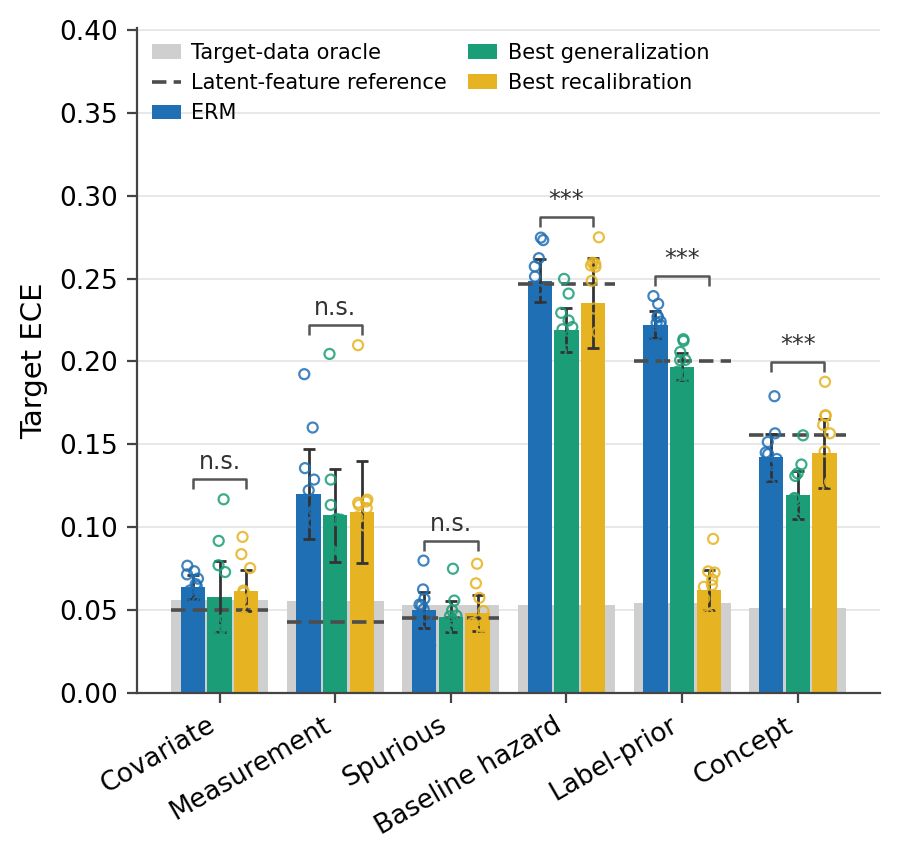

**fig_realmain.png**

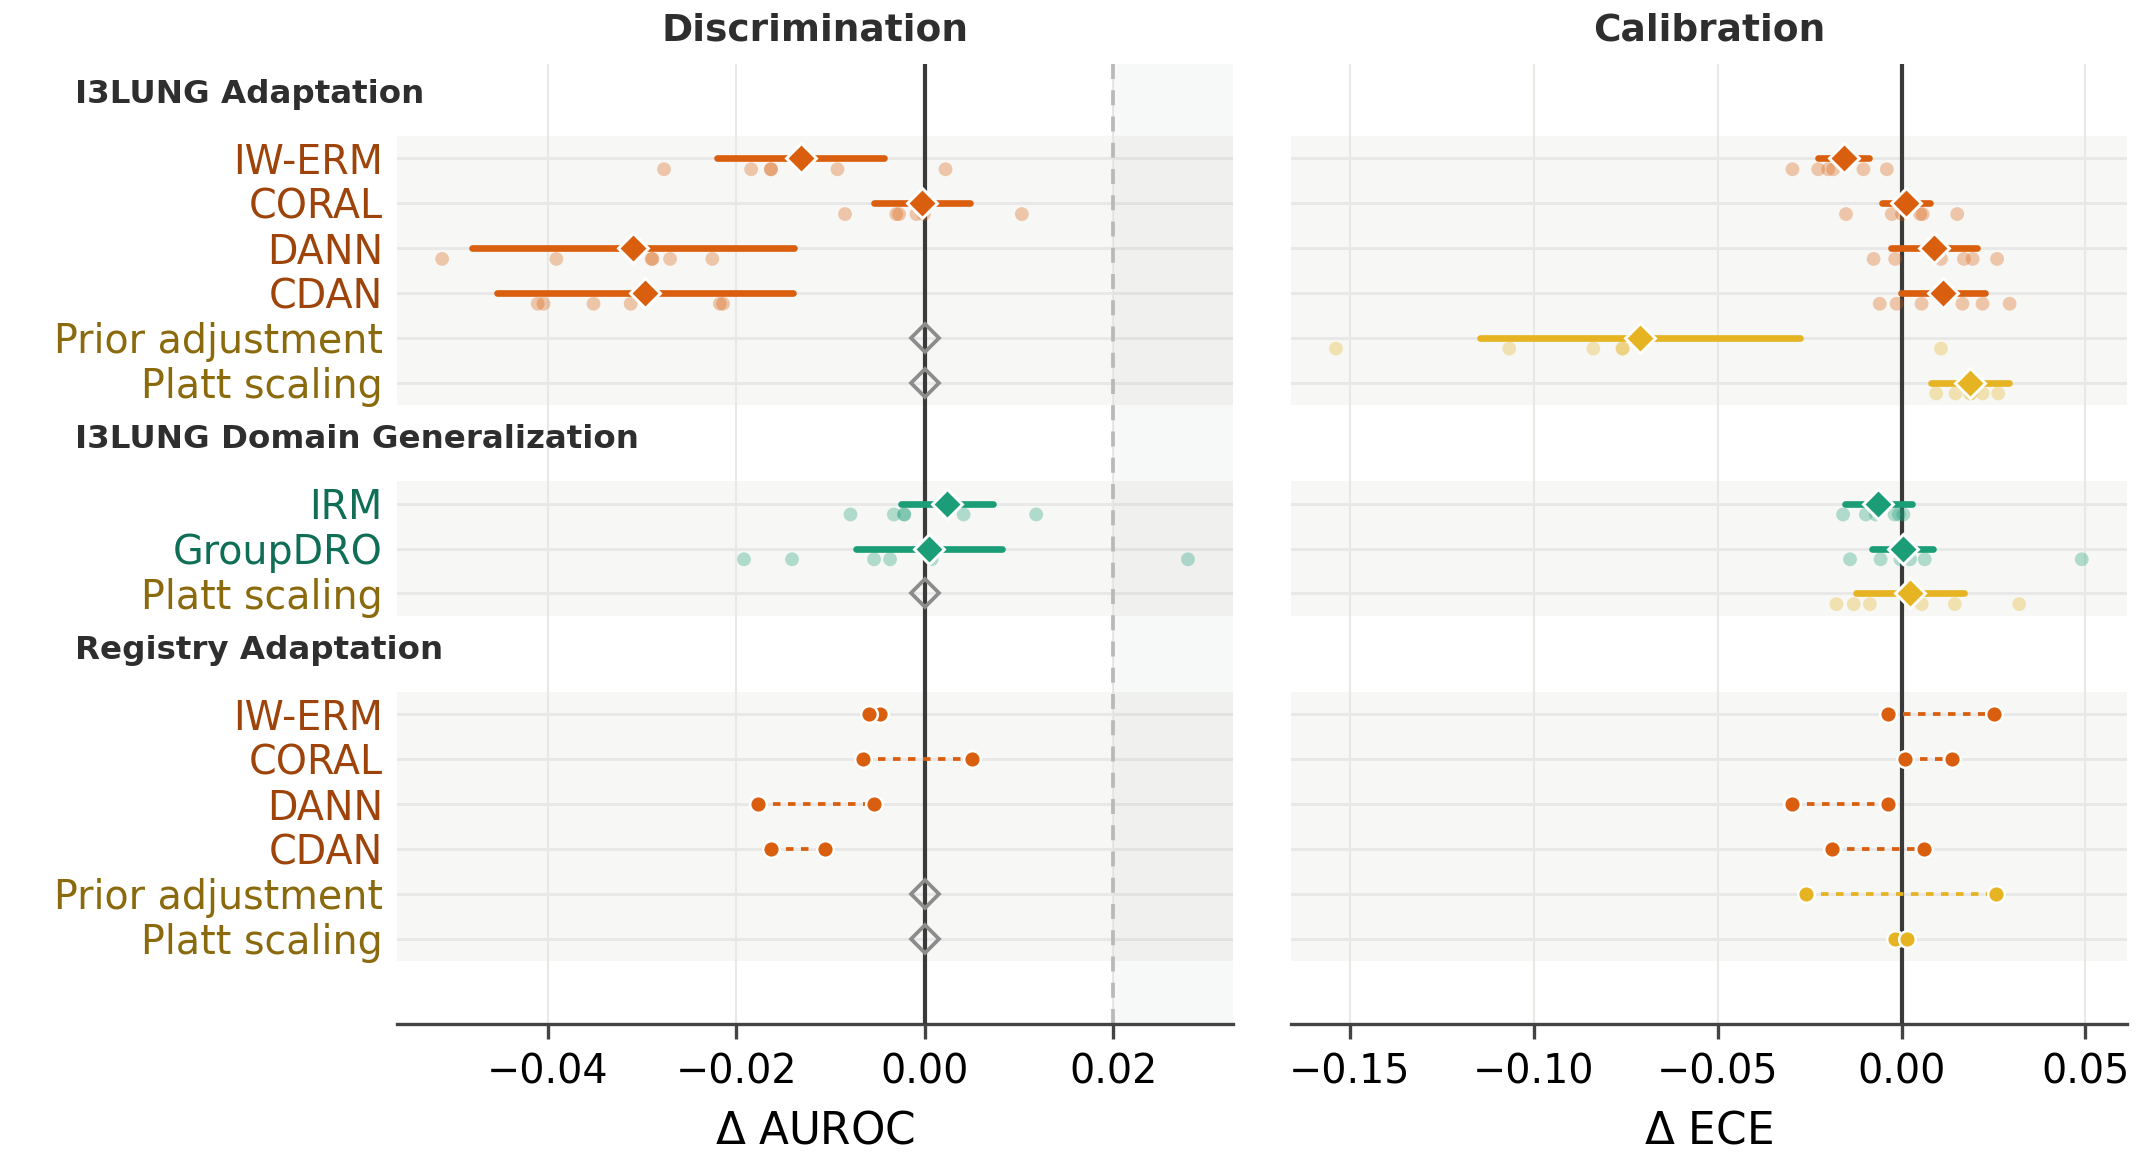

[PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_cal_a.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_cal_b.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_realmain.png')]

In [5]:
run('_gen_fig_realmain.py')

wrote /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_i3lung_disc.pdf  (2.18 in tall, 6 methods)
wrote /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_i3lung_disc.png  (2.18 in tall, 6 methods)
wrote /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_i3lung_cal.pdf  (2.70 in tall, 8 methods)
wrote /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_i3lung_cal.png  (2.70 in tall, 8 methods)
wrote /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_registry_disc.pdf  (1.66 in tall, 4 methods)
wrote /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_registry_disc.png  (1.66 in tall, 4 methods)
wrote /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_registry_cal.pdf  (2.18 in tall, 6 methods)
wrote /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_registry_cal.png  (2.18 in tall, 6 methods)


**fig_cal_b.png**

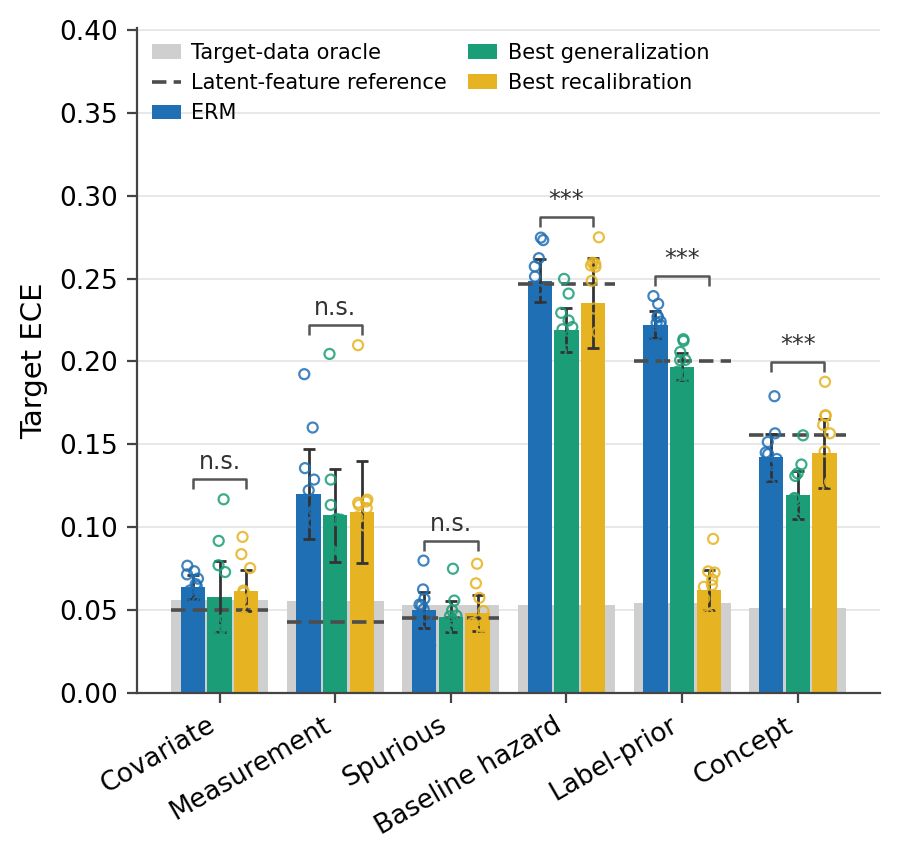

**fig_i3lung_cal.png**

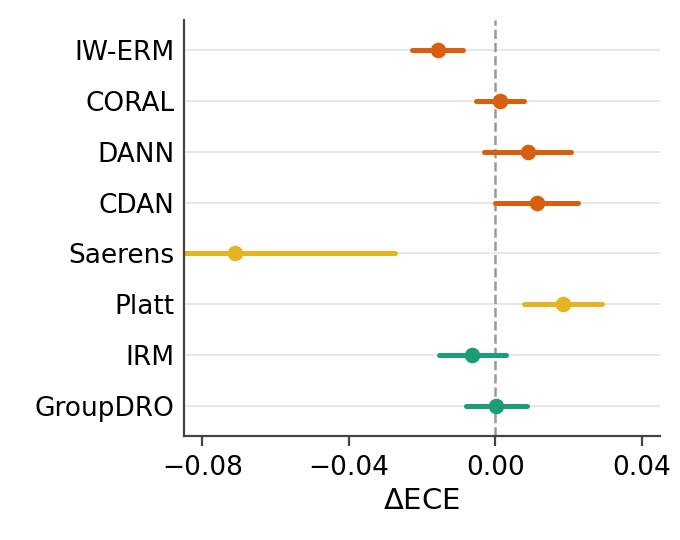

**fig_i3lung_disc.png**

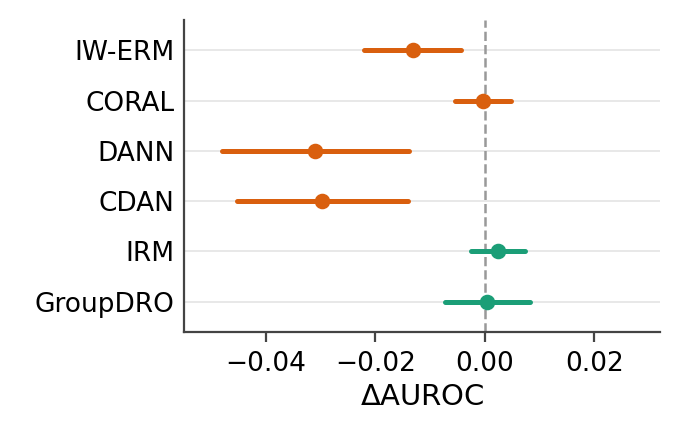

**fig_realmain.png**

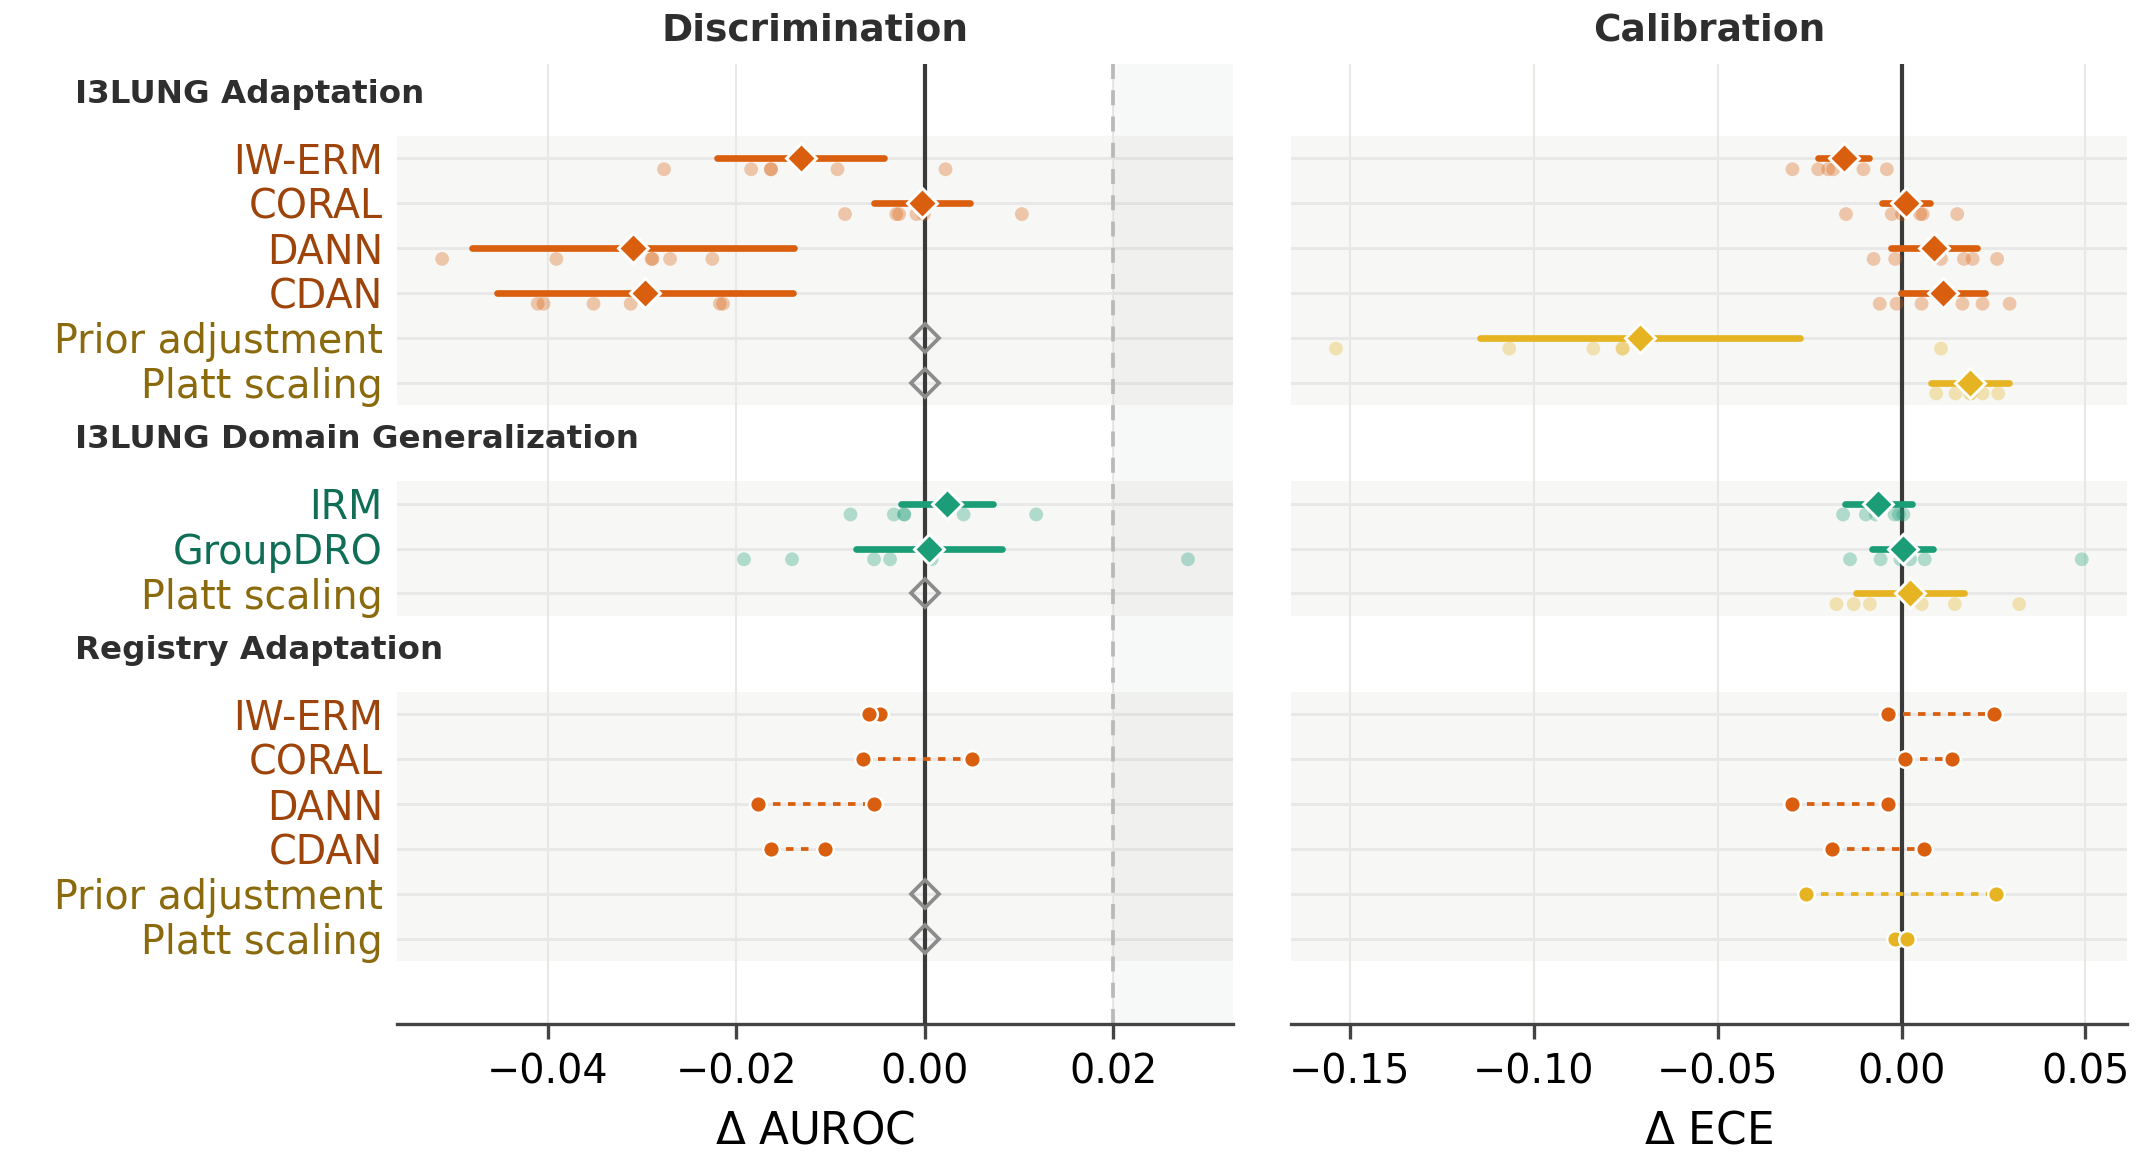

**fig_registry_cal.png**

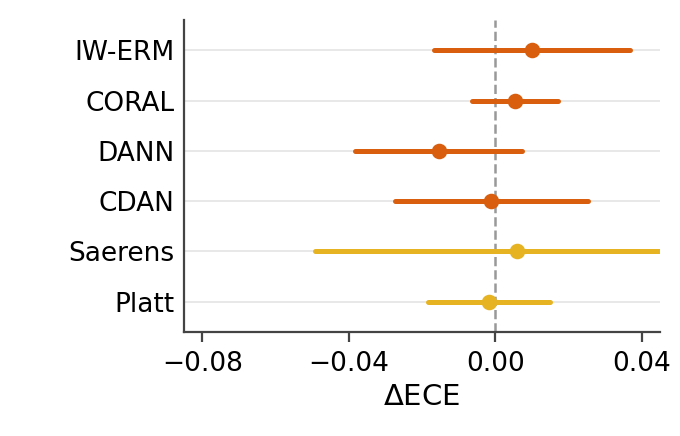

**fig_registry_disc.png**

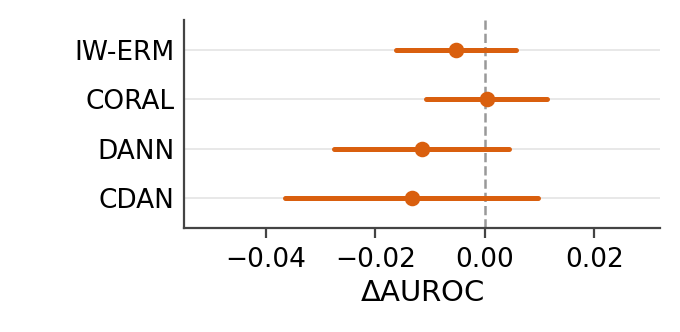

[PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_cal_b.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_i3lung_cal.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_i3lung_disc.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_realmain.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_registry_cal.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_registry_disc.png')]

In [6]:
run('_gen_fig_realdata_panels.py')

## 3. What a deployment can measure

Covariate distance between two centres against the discrimination ERM loses
going from one to the other. Inputs: `i3lung_*_shiftdiag.csv`, `i3lung_*_summary.csv`.

scritto /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_predictability.{pdf,png}   30 transfer, Spearman -0.424


**fig_i3lung_cal.png**

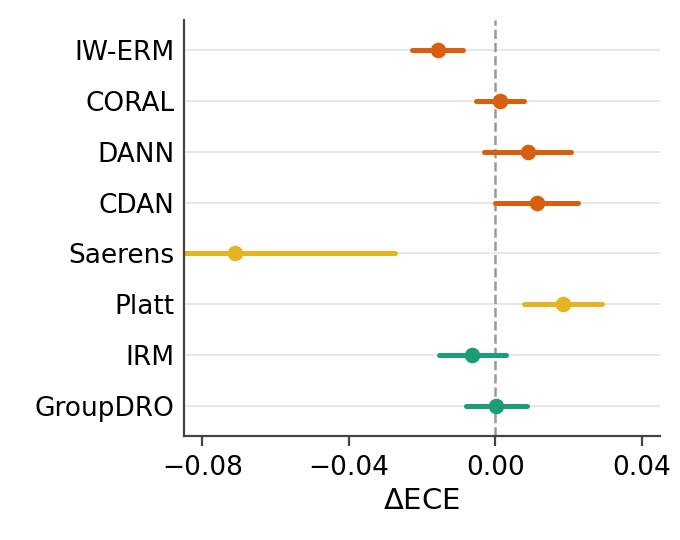

**fig_i3lung_disc.png**

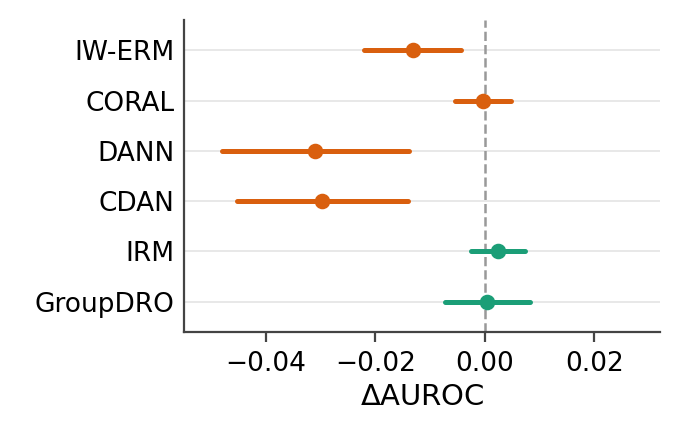

**fig_predictability.png**

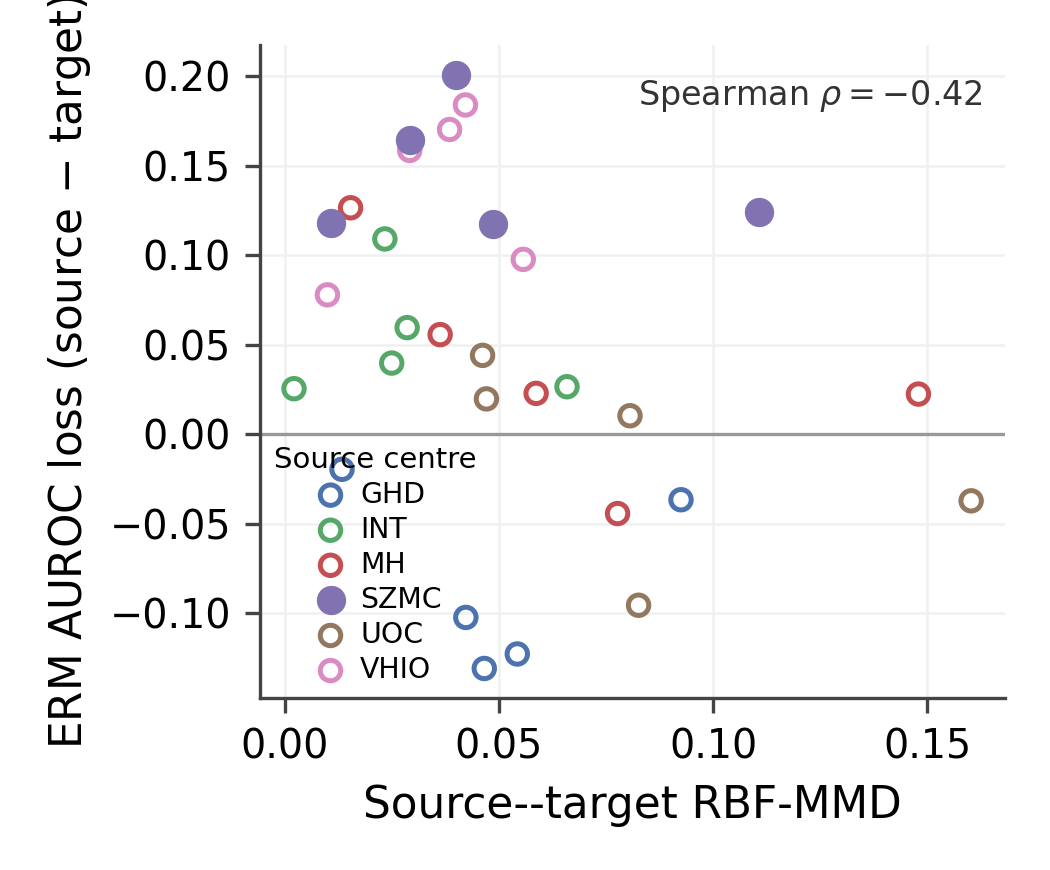

**fig_realmain.png**

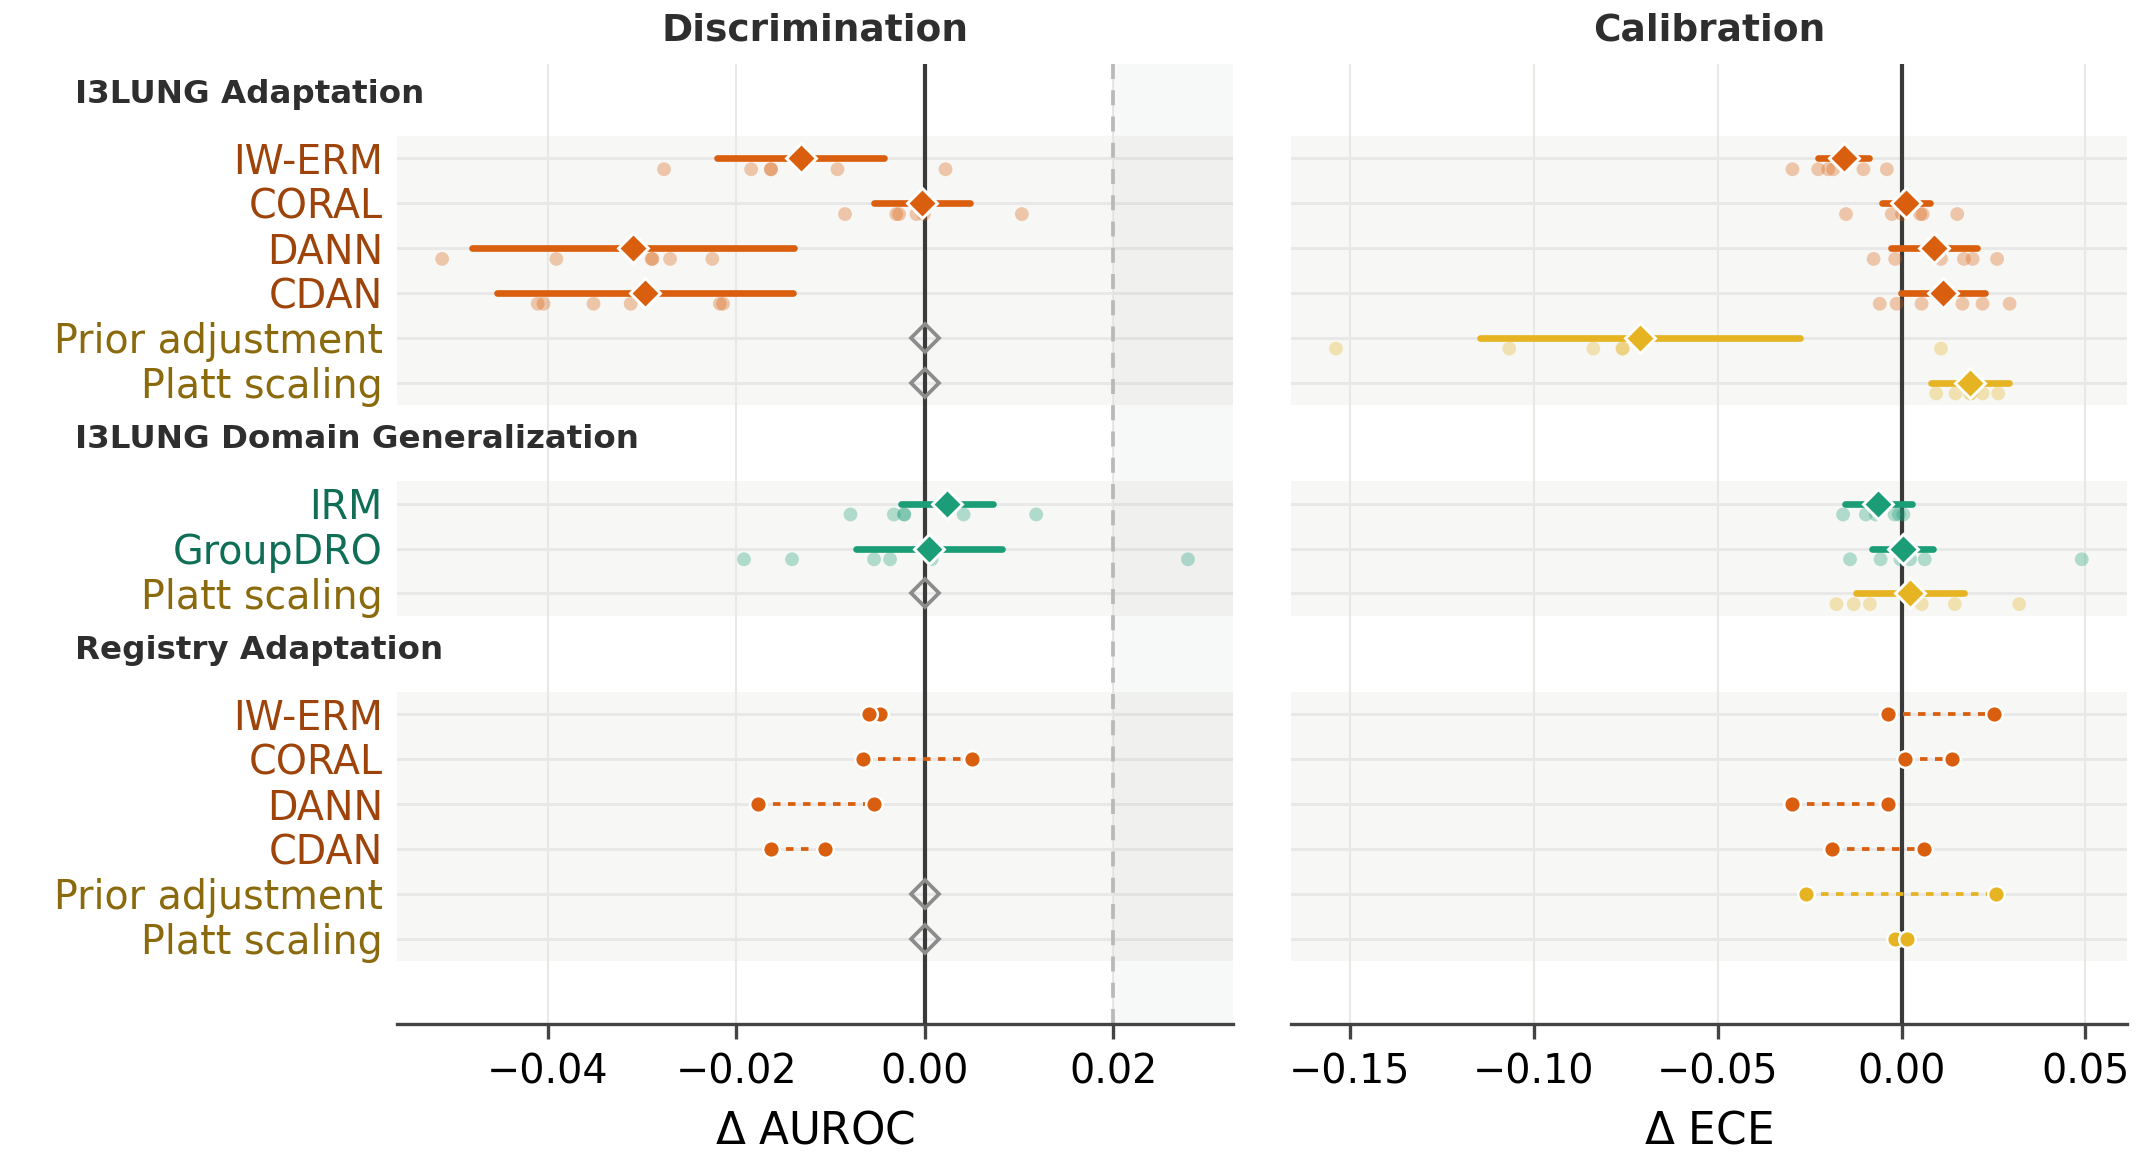

**fig_registry_cal.png**

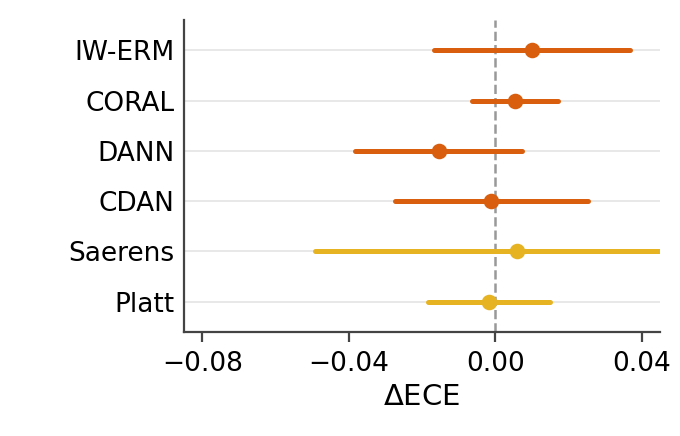

**fig_registry_disc.png**

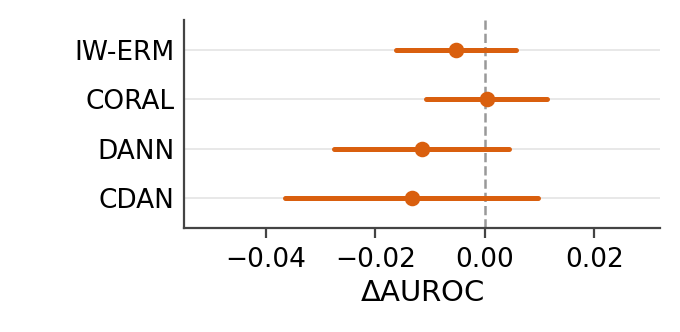

[PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_i3lung_cal.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_i3lung_disc.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_predictability.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_realmain.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_registry_cal.png'),
 PosixPath('/home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_registry_disc.png')]

In [7]:
run('_gen_fig_predictability.py')

## 4. Remaining figures

Shift diagnostics on I3LUNG, the sample-size sweep, and the failure decomposition.
Some of these appear only in the appendix.

In [8]:
for s in ('_gen_fig_i3lung_shift.py', '_gen_fig_nsweep.py',
          '_gen_fig_whyfails.py', '_gen_fig3_dissociation.py',
          '_gen_fig_real.py'):
    display(Markdown(f'### {s}'))
    run(s, show=False)

### _gen_fig_i3lung_shift.py

fig_i3lung_shift da shift_audit_transfers.csv (30 transfer)

  disaccordo fra le due direzioni: mediana 29.7%, massimo 91.8%  (la matrice mostra la media)

  centro        n   survival            IC 95%
  GHD         430      0.577   [0.530, 0.623]
  INT         668      0.644   [0.607, 0.679]
  VHIO        205      0.693   [0.626, 0.752]
  UOC         240      0.758   [0.700, 0.808]
  MH          191      0.796   [0.733, 0.847]
  SZMC        238      0.840   [0.788, 0.881]

  MMD: min 0.0046  mediana 0.0411  max 0.1541

  scritto /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_i3lung_shift_a.pdf
  scritto /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_i3lung_shift_a.png
  scritto /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_i3lung_shift_b.pdf
  scritto /home/ludovica/shift-surv-benchmark/outputs/figures/paper/fig_i3lung_shift_b.png


**fig_i3lung_cal.png**

**fig_i3lung_disc.png**

**fig_i3lung_shift_a.png**

**fig_i3lung_shift_b.png**

... (29 outputs left out)

**fig_swarm_source.png**

**fig_swarm_target.png**

**fig_whyfails_a.png**

**fig_whyfails_b.png**

## Inventory

Everything currently in `outputs/figures/paper/`, with the time it was written.

In [9]:
rows = sorted(FIGS.glob('*.pdf'))
print(f"{len(rows)} figure\n")
for f in rows:
    age = (time.time() - f.stat().st_mtime) / 3600
    print(f'  {f.name:<34} {f.stat().st_size/1024:6.0f} KB   scritta {age:5.1f} h fa')

22 figure

  fig3_dissociation.pdf                  17 KB   scritta   0.0 h fa
  fig_cal_a.pdf                          26 KB   scritta   0.0 h fa
  fig_cal_b.pdf                          26 KB   scritta   0.0 h fa
  fig_disc_a.pdf                         23 KB   scritta   0.0 h fa
  fig_disc_b.pdf                         23 KB   scritta   0.0 h fa
  fig_heatmap.pdf                        20 KB   scritta   0.0 h fa
  fig_i3lung_cal.pdf                     14 KB   scritta   0.0 h fa
  fig_i3lung_disc.pdf                    11 KB   scritta   0.0 h fa
  fig_i3lung_shift_a.pdf                 14 KB   scritta   0.0 h fa
  fig_i3lung_shift_b.pdf                 13 KB   scritta   0.0 h fa
  fig_nsweep_a.pdf                       18 KB   scritta   0.0 h fa
  fig_nsweep_b.pdf                       17 KB   scritta   0.0 h fa
  fig_predictability.pdf                 21 KB   scritta   0.0 h fa
  fig_real_auroc.pdf                     15 KB   scritta   0.0 h fa
  fig_real_ece.pdf                   